# Análisis exploratorio - Telco Customer Churn

**Sebastián Estrada García**

Tecnológico de Monterrey

TC5061 Operaciones de Aprendizaje Automático

## Introducción

Cuando un cliente cancela su servicio, la empresa no solo deja de recibir su pago mensual: también pierde todo lo que invirtió para conseguirlo. A este fenómeno se le conoce como *churn*, y en industrias de suscripción, como las telecomunicaciones, es uno de los indicadores que más se vigilan. Retener a un cliente suele costar mucho menos que conseguir uno nuevo, así que saber a tiempo quién está por irse tiene un valor muy concreto.

En este notebook trabajamos con el dataset [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), publicado en Kaggle, que describe a más de siete mil clientes de una compañía telefónica: qué servicios contrataron, cómo pagan, cuánto tiempo llevan con la empresa y si se fueron en el último mes. La pregunta que nos guía es sencilla: **¿podemos anticipar qué clientes están por cancelar?** Si la respuesta es sí, el equipo de retención podría enfocar sus esfuerzos en ellos antes de perderlos.

Este notebook se dedica solo a la exploración: describe los datos, busca qué variables se relacionan con la cancelación e identifica los problemas de calidad. El entrenamiento y el registro de los experimentos viven en el script `telco_churn/modeling/train.py`, que se ejecuta desde la línea de comandos y registra cada corrida en MLflow. Las decisiones de limpieza que tomamos aquí están implementadas en `telco_churn/dataset.py`, de modo que el notebook y el script usan exactamente la misma limpieza.

## 1. Análisis exploratorio

Antes de entrenar cualquier modelo necesitamos conocer los datos. En esta sección cargamos el dataset, describimos su estructura y el significado de cada variable, y usamos estadísticas y gráficas para entender cómo se distribuyen las variables, cuáles se relacionan con la cancelación y qué problemas de calidad habrá que resolver en la limpieza.

### Librerías y configuración

Importamos las librerías que usaremos y las funciones del proyecto que cargan y limpian los datos, las mismas que usa el script de entrenamiento. También definimos un estilo común para las gráficas.

In [1]:
# Librerías para manipular datos, calcular estadísticas y graficar
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# Funciones del proyecto: la misma carga y limpieza que usa el script de entrenamiento
from telco_churn.config import DATOS_CRUDOS, NUMERICAS
from telco_churn.dataset import cargar_datos, limpiar_datos

# Colores de las gráficas: uno para cada tipo de cliente y otros de apoyo
COLOR_SE_QUEDA, COLOR_SE_VA, COLOR_NEUTRO = "#2a78d6", "#eb6834", "#4a3aa7"
COLORES_CHURN = {"No": COLOR_SE_QUEDA, "Yes": COLOR_SE_VA}
ETIQUETAS_CHURN = {"No": "Se queda", "Yes": "Se va"}
TINTA, TINTA_2, TINTA_SUAVE, REJILLA, EJE, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

# Estilo común de las gráficas: fondo claro, rejilla tenue y sin bordes innecesarios
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "figure.dpi": 110, "savefig.dpi": 150,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "axes.titlelocation": "left", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "axes.edgecolor": EJE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})
LEYENDA_CHURN = [Line2D([0], [0], color=COLORES_CHURN[k], linewidth=2, label=v) for k, v in ETIQUETAS_CHURN.items()]

### Carga de los datos

Se importan los datos a partir del archivo CSV descargado de [Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), que el proyecto guarda sin modificar en `data/raw/`. Más adelante revisaremos su calidad sin alterar esta versión original.

In [2]:
# Leemos el archivo tal como viene, sin indicar tipos, para ver cómo lo interpreta pandas
df_raw = cargar_datos(DATOS_CRUDOS)

print(f"Registros (clientes): {df_raw.shape[0]:,}")
print(f"Variables (columnas): {df_raw.shape[1]}")
df_raw.head()

Registros (clientes): 7,043
Variables (columnas): 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Estructura del dataset

Describimos la estructura del dataset: el número de registros y de variables, el tipo con el que pandas leyó cada una, cuántos valores distintos tiene, si le faltan datos y qué significa.

In [3]:
# Significado de cada variable, según la descripción del dataset
SIGNIFICADO = {
    "customerID": "Identificador único del cliente",
    "gender": "Género del cliente",
    "SeniorCitizen": "Si es adulto mayor (1 = sí, 0 = no)",
    "Partner": "Si tiene pareja",
    "Dependents": "Si tiene dependientes económicos",
    "tenure": "Meses que lleva como cliente",
    "PhoneService": "Si tiene servicio telefónico",
    "MultipleLines": "Si tiene varias líneas telefónicas",
    "InternetService": "Tipo de internet: DSL, fibra óptica o ninguno",
    "OnlineSecurity": "Si contrató seguridad en línea",
    "OnlineBackup": "Si contrató respaldo en línea",
    "DeviceProtection": "Si contrató protección de equipo",
    "TechSupport": "Si contrató soporte técnico",
    "StreamingTV": "Si contrató televisión por streaming",
    "StreamingMovies": "Si contrató películas por streaming",
    "Contract": "Plazo del contrato: mes a mes, un año o dos años",
    "PaperlessBilling": "Si recibe su factura en formato electrónico",
    "PaymentMethod": "Forma de pago",
    "MonthlyCharges": "Monto que paga cada mes",
    "TotalCharges": "Monto total pagado durante toda su permanencia",
    "Churn": "Si se fue en el último mes (la variable a predecir)",
}


def celdas_en_blanco(serie: pd.Series) -> int:
    """Cuenta celdas de texto vacías o con solo espacios, que pandas no reconoce como faltantes."""
    if pd.api.types.is_numeric_dtype(serie):
        return 0
    return int(serie.str.strip().eq("").sum())


# Una fila por variable: tipo, valores distintos, faltantes, ejemplos y significado
estructura = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "valores distintos": df_raw.nunique(),
    "nulos": df_raw.isna().sum(),
    "celdas en blanco": [celdas_en_blanco(df_raw[col]) for col in df_raw.columns],
    "ejemplos": [", ".join(map(str, df_raw[col].unique()[:3])) for col in df_raw.columns],
    "significado": pd.Series(SIGNIFICADO),
})
display(estructura)

,tipo,valores distintos,nulos,celdas en blanco,ejemplos,significado
customerID,str,7043,0,0,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK",Identificador único del cliente
gender,str,2,0,0,"Female, Male",Género del cliente
SeniorCitizen,int64,2,0,0,"0, 1","Si es adulto mayor (1 = sí, 0 = no)"
Partner,str,2,0,0,"Yes, No",Si tiene pareja
Dependents,str,2,0,0,"No, Yes",Si tiene dependientes económicos
tenure,int64,73,0,0,"1, 34, 2",Meses que lleva como cliente
PhoneService,str,2,0,0,"No, Yes",Si tiene servicio telefónico
MultipleLines,str,3,0,0,"No phone service, No, Yes",Si tiene varias líneas telefónicas
InternetService,str,3,0,0,"DSL, Fiber optic, No","Tipo de internet: DSL, fibra óptica o ninguno"
OnlineSecurity,str,3,0,0,"No, Yes, No internet service",Si contrató seguridad en línea


Podemos observar que el dataset tiene **7,043 clientes y 21 variables**. Una es el identificador del cliente, `Churn` es la variable que queremos predecir y las 19 restantes describen al cliente: 3 son numéricas (antigüedad, cargo mensual y cargo total) y 16 son categóricas (datos demográficos, servicios contratados, tipo de contrato y forma de pago).

A simple vista no faltan datos, porque ninguna columna tiene nulos, pero aparecen dos detalles que habrá que resolver en la limpieza. `TotalCharges` se leyó como texto aunque es un monto de dinero, y tiene 11 celdas en blanco que pandas no cuenta como faltantes. Además, `SeniorCitizen` usa 0 y 1, mientras que el resto de las variables de sí/no usan *Yes* y *No*.

### La variable objetivo

Revisamos cuántos clientes se quedaron y cuántos se fueron, porque esa proporción influye en cómo dividimos los datos y en cómo medimos el desempeño del modelo.

In [4]:
# Conteo y porcentaje de cada clase
conteo = df_raw["Churn"].value_counts()
porcentaje = df_raw["Churn"].value_counts(normalize=True)
for clase in ["No", "Yes"]:
    print(f"{ETIQUETAS_CHURN[clase]:<9}{conteo[clase]:>6,} clientes  ({porcentaje[clase]:.1%})")

Se queda  5,174 clientes  (73.5%)
Se va     1,869 clientes  (26.5%)


Podemos observar que **se va uno de cada cuatro clientes** (26.5%). Las clases no están equilibradas: hay casi tres clientes que se quedan por cada uno que se va. Esto importa porque un modelo que dijera siempre "se queda" acertaría el 73.5% de las veces sin detectar a ningún cliente en riesgo. Lo tendremos en cuenta al elegir la métrica y al dividir los datos.

### Estadísticas descriptivas

Generamos estadísticas descriptivas de las variables numéricas y comparamos sus valores típicos entre los clientes que se quedan y los que se van. Para poder analizar `TotalCharges`, la convertimos a número en una copia exploratoria; la corrección formal se hace en la limpieza.

In [5]:
# Copia para explorar: convertimos TotalCharges a número (las celdas en blanco quedan como faltantes)
df_eda = df_raw.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"].str.strip(), errors="coerce")
se_va = df_eda["Churn"].eq("Yes")

CATEGORICAS = [col for col in df_raw.columns if col not in NUMERICAS + ["customerID", "Churn"]]
NOMBRES = {"tenure": "Antigüedad (meses)", "MonthlyCharges": "Cargo mensual", "TotalCharges": "Cargo total"}

# Resumen de las numéricas: promedio, dispersión, mínimo, cuartiles y máximo
ENCABEZADOS = {"count": "registros", "mean": "promedio", "std": "desviación estándar", "min": "mínimo",
               "25%": "cuartil 1", "50%": "mediana", "75%": "cuartil 3", "max": "máximo"}
print("Resumen de las variables numéricas")
display(df_eda[NUMERICAS].describe().T.rename(index=NOMBRES, columns=ENCABEZADOS).round(2))

# Mediana de cada variable según si el cliente se quedó o se fue
print("Mediana por tipo de cliente")
display(df_eda.groupby("Churn")[NUMERICAS].median().rename(index=ETIQUETAS_CHURN, columns=NOMBRES)
        .rename_axis("tipo de cliente").round(2))

Resumen de las variables numéricas


,registros,promedio,desviación estándar,mínimo,cuartil 1,mediana,cuartil 3,máximo
Antigüedad (meses),7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
Cargo mensual,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
Cargo total,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80


Mediana por tipo de cliente


,Antigüedad (meses),Cargo mensual,Cargo total
tipo de cliente,,,
Se queda,38.0,64.43,1683.60
Se va,10.0,79.65,703.55


Podemos observar que hay clientes de todas las antigüedades, desde recién llegados hasta clientes de seis años (72 meses), y que la mitad paga más de 70 al mes. El cargo total varía muchísimo, de 18 a más de 8,600, porque se acumula mes con mes: su promedio (2,283) queda muy por encima de su mediana (1,397), señal de que unos pocos clientes antiguos tienen montos muy altos.

La comparación entre grupos es lo más revelador. Un cliente típico que se va lleva **10 meses** con la empresa, contra **38** de uno que se queda, y paga más cada mes (79.65 contra 64.43). Su cargo total es menor, pero no porque gaste menos, sino porque se va antes.

### Distribución de las variables numéricas

Generamos visualizaciones que permiten entender la distribución de cada variable numérica, comparando la forma que tiene entre los clientes que se quedan y los que se van.

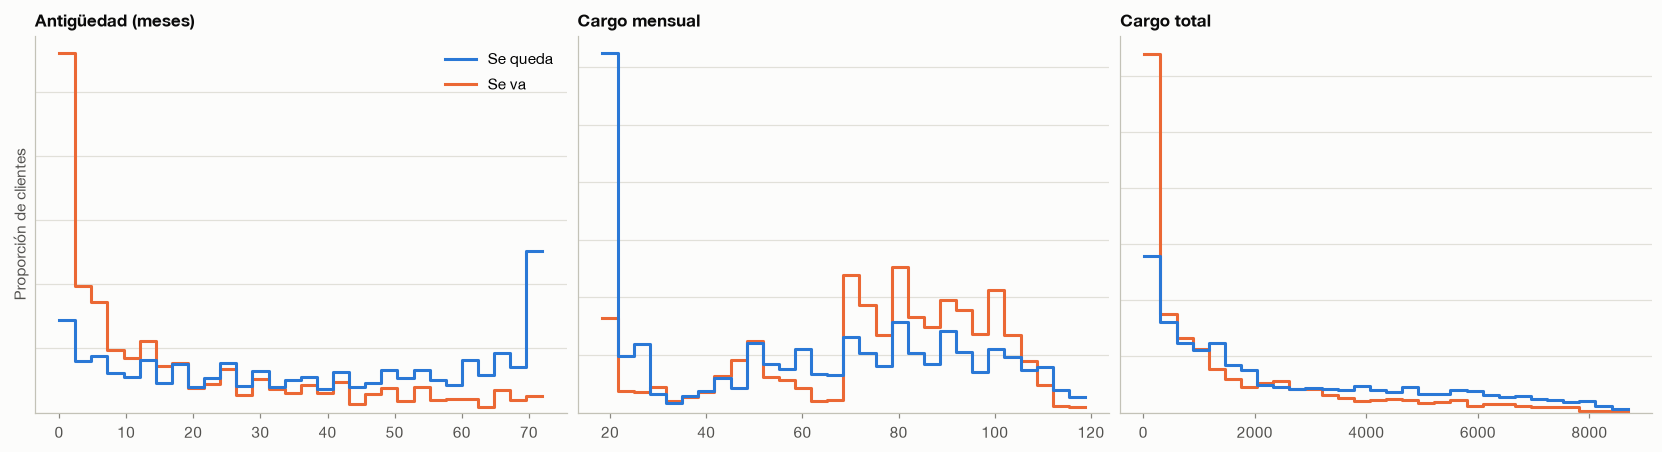

Se va el 47.4% de los clientes en su primer año, contra el 9.5% de quienes llevan más de cuatro años.
De todos los clientes que se van, el 55.5% estaba en su primer año.


In [6]:
# Un histograma por variable; cada clase se normaliza por separado para poder compararlas
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for eje, col in zip(ejes, NUMERICAS):
    sns.histplot(data=df_eda, x=col, hue="Churn", hue_order=["No", "Yes"], palette=COLORES_CHURN,
                 element="step", fill=False, stat="density", common_norm=False, bins=30,
                 linewidth=2, legend=False, ax=eje)
    eje.set_title(NOMBRES[col])
    eje.set_xlabel("")
    eje.set_ylabel("Proporción de clientes" if col == "tenure" else "")
    eje.tick_params(axis="y", left=False, labelleft=False)
    eje.grid(axis="x", visible=False)
ejes[0].legend(handles=LEYENDA_CHURN, loc="upper right")
plt.show()

# Cifras que resumen lo que se ve en la gráfica de antigüedad
primer_anio = df_eda["tenure"] <= 12
print(f"Se va el {se_va[primer_anio].mean():.1%} de los clientes en su primer año, "
      f"contra el {se_va[df_eda['tenure'] > 48].mean():.1%} de quienes llevan más de cuatro años.")
print(f"De todos los clientes que se van, el {primer_anio[se_va].mean():.1%} estaba en su primer año.")

Podemos observar que las cancelaciones se concentran en los primeros meses: casi la mitad de los clientes que están en su primer año se va (47.4%), contra menos del 10% de quienes llevan más de cuatro años, y más de la mitad de todas las cancelaciones ocurre en el primer año. Entre quienes se quedan destaca un grupo grande con 70 a 72 meses, clientes que llevan con la empresa todo el periodo que cubren los datos.

En el cargo mensual, los clientes que se quedan se agrupan sobre todo alrededor de 20, que corresponde a quienes no tienen internet, mientras que los que se van se concentran entre 70 y 105. En el cargo total, los que se van se amontonan en montos bajos, lo cual es consecuencia de su poca antigüedad más que de un gasto menor.

### Relación entre las variables categóricas y la cancelación

Para cada variable categórica calculamos qué porcentaje de los clientes de cada categoría se fue. La línea gris marca el promedio general (26.5%): las barras que la superan señalan grupos con más riesgo. Ordenamos las variables de mayor a menor diferencia entre sus categorías y etiquetamos solo la categoría de mayor riesgo de cada una.

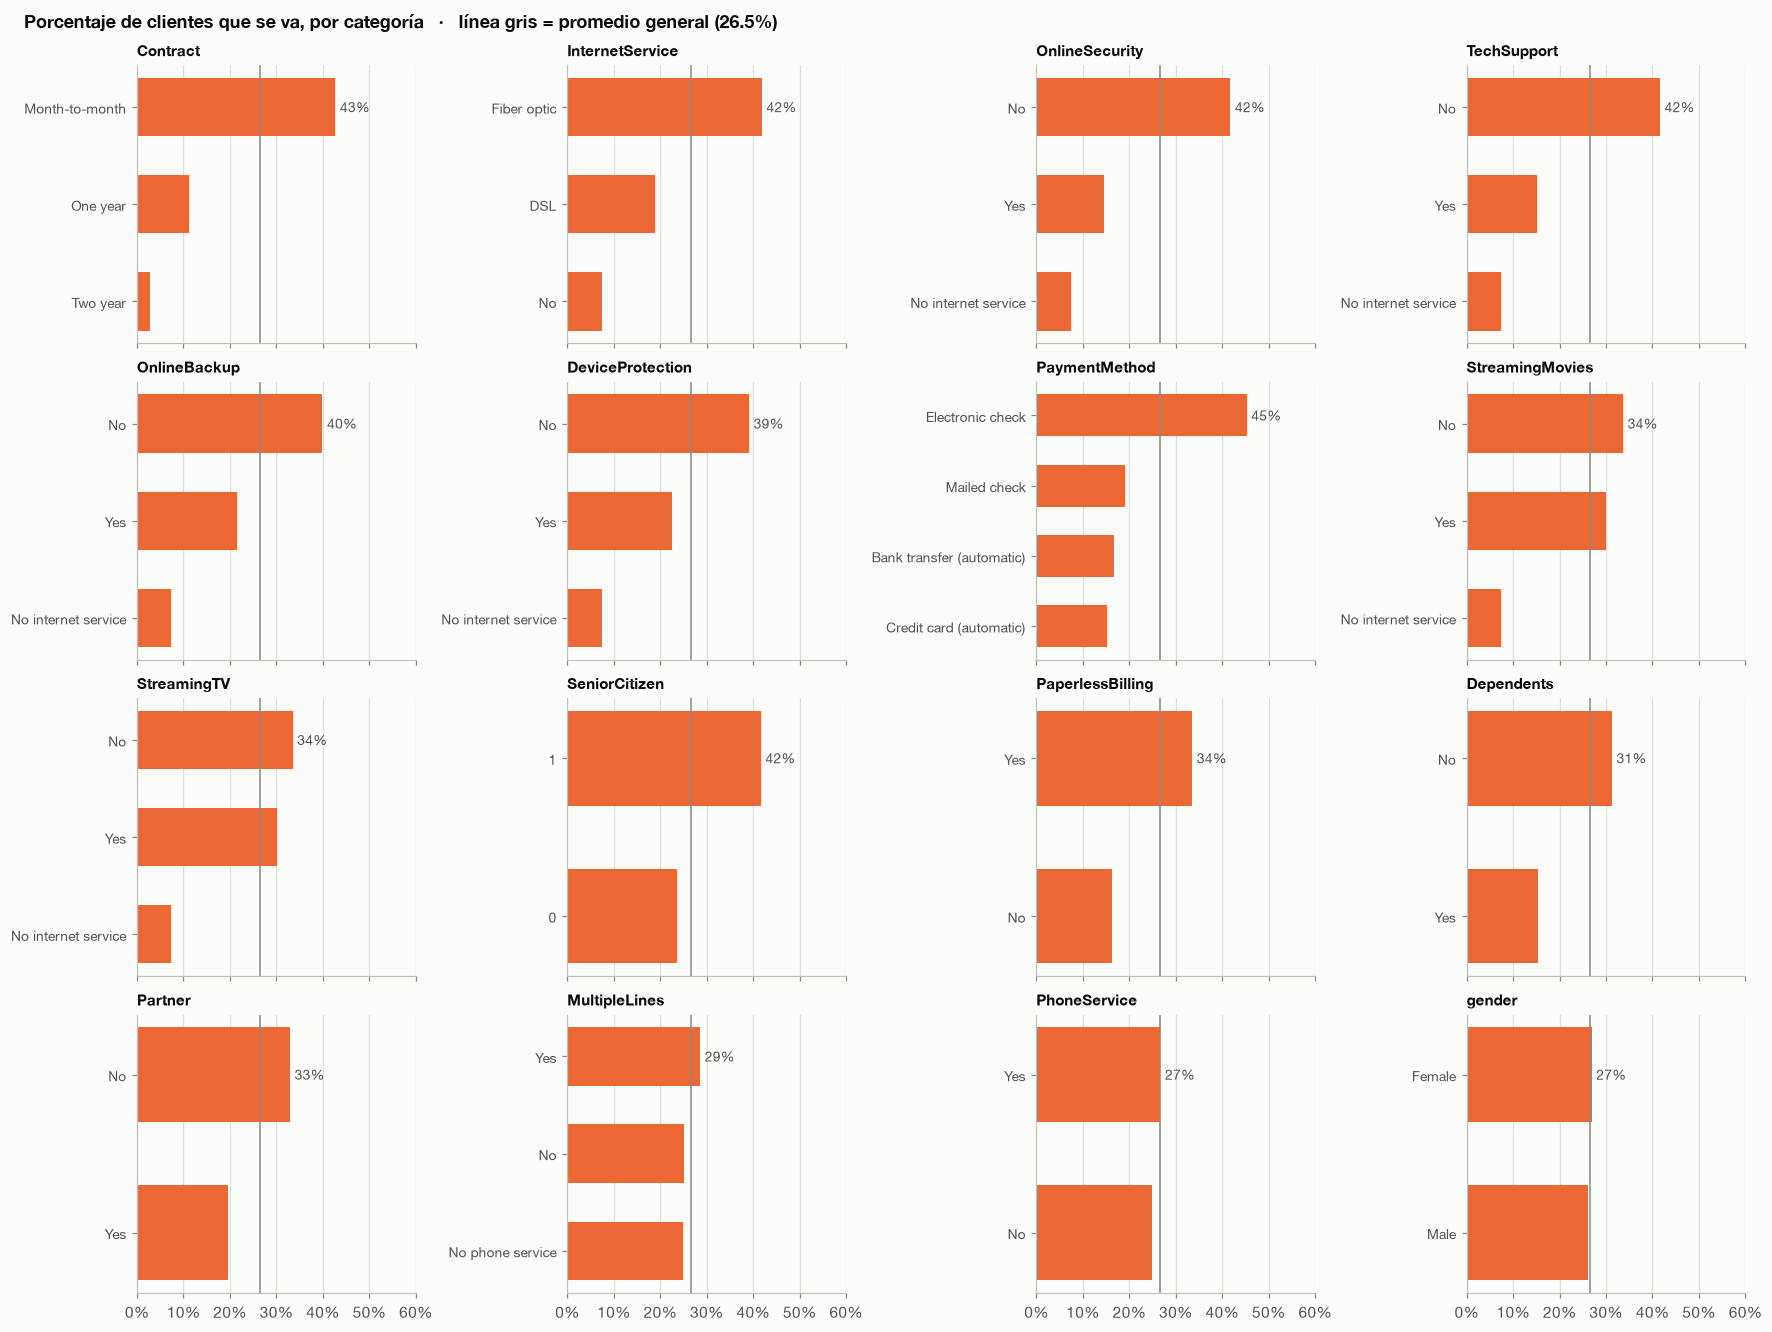

In [7]:
# Porcentaje de clientes que se fue dentro de cada categoría, para cada variable
tasa_global = se_va.mean()
tasas_por_variable = {col: se_va.groupby(df_eda[col].astype(str)).mean().sort_values() for col in CATEGORICAS}
# Ordenamos las variables según qué tan distintas son sus categorías entre sí
orden = sorted(CATEGORICAS, key=lambda col: tasas_por_variable[col].max() - tasas_por_variable[col].min(), reverse=True)

fig, ejes = plt.subplots(4, 4, figsize=(16, 12), sharex=True, layout="constrained")
for eje, col in zip(ejes.flat, orden):
    tasas = tasas_por_variable[col]
    eje.barh(tasas.index, tasas.values, color=COLOR_SE_VA, height=0.6)
    eje.axvline(tasa_global, color=TINTA_SUAVE, linewidth=1)
    eje.text(tasas.iloc[-1] + 0.01, len(tasas) - 1, f"{tasas.iloc[-1]:.0%}", va="center", fontsize=9, color=TINTA_2)
    eje.set_title(col, fontsize=10)
    eje.tick_params(axis="y", labelsize=9)
    eje.grid(axis="y", visible=False)
ejes[0, 0].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ejes[0, 0].set_xlim(0, 0.6)
fig.suptitle(f"Porcentaje de clientes que se va, por categoría   ·   línea gris = promedio general ({tasa_global:.1%})",
             x=0.01, ha="left", fontweight="bold", color=TINTA)
plt.show()

Podemos observar un perfil de riesgo muy claro:

- **El tipo de contrato es lo que más marca la diferencia.** Con contrato mes a mes se va el 42.7% de los clientes; con contrato de un año, el 11.3%, y con uno de dos años, apenas el 2.8%.
- **El tipo de internet también pesa.** Con fibra óptica se va el 41.9%, más del doble que con DSL (19.0%), y quien no tiene internet casi nunca se va (7.4%).
- **Los servicios de protección retienen.** Sin seguridad en línea o sin soporte técnico se va alrededor del 42% de los clientes; con ellos, cerca del 15%.
- **La forma de pago importa.** Quienes pagan con cheque electrónico tienen la tasa más alta de todas (45.3%), contra 15% a 17% de quienes pagan de forma automática.
- **Algunas variables casi no dicen nada.** El género, tener servicio telefónico y tener varias líneas muestran prácticamente el mismo porcentaje en todas sus categorías.

También vemos que la categoría "No internet service" se repite en seis variables con exactamente la misma tasa (7.4%): son los mismos 1,526 clientes sin internet, contados en seis columnas distintas.

### Relaciones entre las variables numéricas

Medimos qué tan relacionadas están las variables numéricas entre sí y con la cancelación (codificada como 1 si el cliente se va y 0 si se queda), usando la correlación: un valor cercano a 1 indica que dos variables suben juntas, cercano a −1 que una baja cuando la otra sube, y cercano a 0 que no tienen relación lineal.

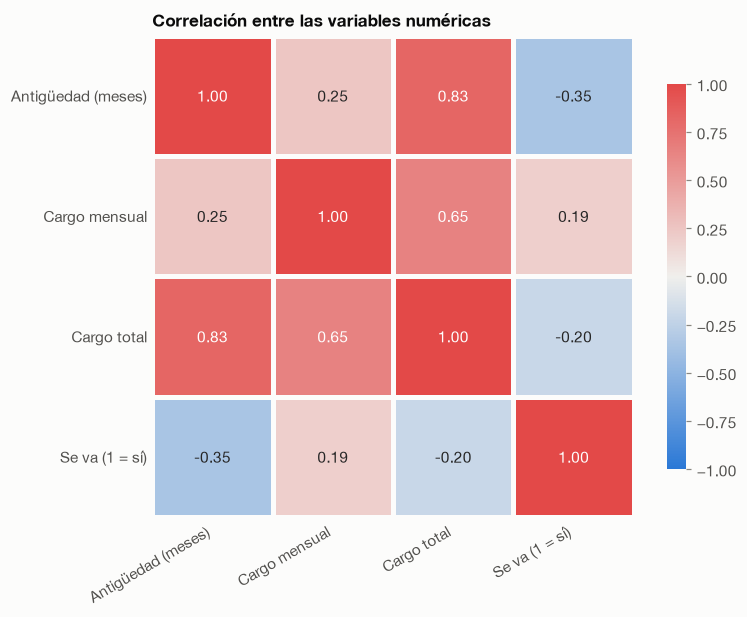

In [8]:
# Matriz de correlación entre las numéricas y la variable objetivo
datos_corr = (df_eda[NUMERICAS].assign(Churn=se_va.astype(int))
              .rename(columns={**NOMBRES, "Churn": "Se va (1 = sí)"}))
mapa_divergente = LinearSegmentedColormap.from_list("azul_gris_rojo", ["#2a78d6", "#f0efec", "#e34948"])

fig, eje = plt.subplots(figsize=(7, 5.5), layout="constrained")
sns.heatmap(datos_corr.corr(), ax=eje, cmap=mapa_divergente, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=2, linecolor=FONDO, cbar_kws={"shrink": 0.8})
eje.set_title("Correlación entre las variables numéricas")
eje.tick_params(axis="both", length=0)
eje.set_xticklabels(eje.get_xticklabels(), rotation=30, ha="right")
eje.set_yticklabels(eje.get_yticklabels(), rotation=0)
plt.show()

Podemos observar que la antigüedad y el cargo total están muy relacionados (0.83). Tiene sentido: el cargo total es, en esencia, lo que el cliente paga cada mes multiplicado por los meses que lleva, así que ambas variables cuentan en buena parte la misma historia.

Respecto a la cancelación, la antigüedad es la variable numérica con la relación más fuerte, y es inversa (−0.35): a más meses como cliente, menos probabilidad de irse. El cargo mensual tiene una relación directa más débil (0.19): pagar más se asocia con irse un poco más.

### Antigüedad y cargo mensual en conjunto

Por último, cruzamos las dos variables numéricas más informativas para ver dónde se ubican los clientes que se van. Usamos un panel para cada tipo de cliente, para que los puntos de un grupo no tapen a los del otro.

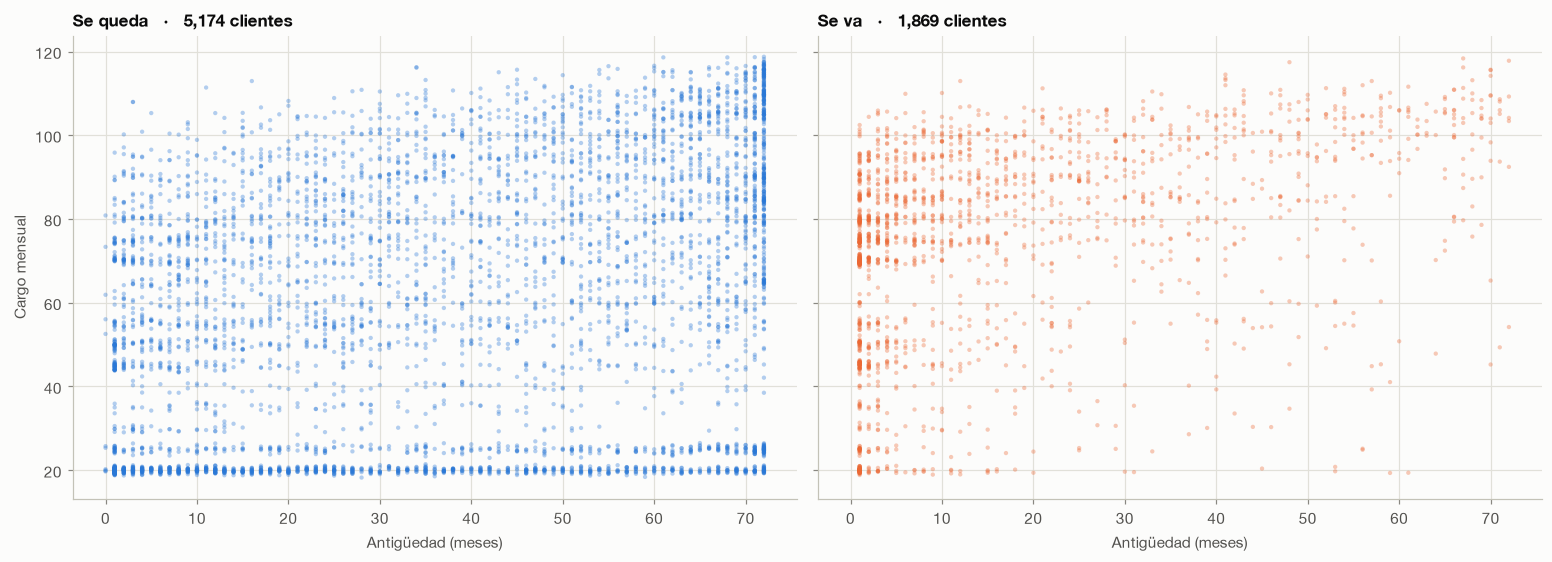

In [9]:
# Diagrama de dispersión: un punto por cliente, separado por tipo de cliente
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True, layout="constrained")
for eje, clase in zip(ejes, ["No", "Yes"]):
    clientes = df_eda[df_eda["Churn"] == clase]
    eje.scatter(clientes["tenure"], clientes["MonthlyCharges"], s=8, alpha=0.35,
                color=COLORES_CHURN[clase], edgecolors="none")
    eje.set_title(f"{ETIQUETAS_CHURN[clase]}   ·   {len(clientes):,} clientes")
    eje.set_xlabel(NOMBRES["tenure"])
ejes[0].set_ylabel(NOMBRES["MonthlyCharges"])
plt.show()

Podemos observar que los clientes que se quedan están repartidos por todo el plano, con una franja muy marcada en cargos de 20 (sin internet) y muchos clientes con varios años de antigüedad. Los que se van, en cambio, se concentran a la izquierda y arriba: **pocos meses como clientes y cargos mensuales altos**, sobre todo entre 70 y 100. Y los pocos que se van después de varios años casi siempre pagan cargos altos. Es decir, el cargo mensual pesa distinto según la antigüedad del cliente.

**En resumen**, el análisis exploratorio muestra que hay señales claras para anticipar la cancelación: los clientes nuevos, con contrato mes a mes, con fibra óptica, que pagan con cheque electrónico y que no tienen servicios de protección son los que más se van. También dejó identificados los problemas de calidad que revisamos a continuación.

## 2. Calidad de los datos

En esta sección identificamos los problemas de calidad del dataset: tipos de dato incorrectos, valores faltantes, registros duplicados y valores atípicos. Para cada uno mostramos la evidencia, tomamos una decisión y explicamos por qué. Todas las decisiones se basan en la lógica del negocio, no en promedios calculados con todos los datos, para no filtrar información del conjunto de prueba al entrenamiento.

Las decisiones no se aplican aquí a mano: están implementadas en la función `limpiar_datos` del proyecto, la misma que usa el script de entrenamiento. Al final de la sección la aplicamos para comprobar el resultado.

### Tipos incorrectos

Identificamos las variables cuyo tipo no corresponde a lo que representan. `TotalCharges` es un monto, pero se leyó como texto, así que revisamos qué valores no se pueden convertir a número. `SeniorCitizen` es una variable de sí/no, pero viene como 0 y 1.

In [10]:
# TotalCharges: qué valores no se pueden convertir a número
texto_original = df_raw["TotalCharges"].str.strip()
no_convertidos = pd.to_numeric(texto_original, errors="coerce").isna()
print(f"TotalCharges se leyó con tipo {df_raw['TotalCharges'].dtype}.")
print(f"Valores que no se pueden convertir a número: {no_convertidos.sum()} "
      f"(su texto original es: {texto_original[no_convertidos].unique().tolist()})")

# SeniorCitizen frente a otra variable de sí/no
print(f"SeniorCitizen toma los valores {sorted(df_raw['SeniorCitizen'].unique().tolist())}, "
      f"mientras que Partner toma {sorted(df_raw['Partner'].unique().tolist())}.")

TotalCharges se leyó con tipo str.
Valores que no se pueden convertir a número: 11 (su texto original es: [''])
SeniorCitizen toma los valores [0, 1], mientras que Partner toma ['No', 'Yes'].


Podemos observar que los únicos valores de `TotalCharges` que no se pueden convertir son las 11 celdas en blanco que detectamos en la estructura: al convertir la columna quedarán como faltantes, que tratamos en el siguiente paso. `SeniorCitizen`, en cambio, usa 0 y 1, mientras que las demás variables de sí/no usan *Yes* y *No*.

**Decisión: convertir `TotalCharges` a número y `SeniorCitizen` a *No* y *Yes*.** Así cada variable tiene el tipo que corresponde a lo que representa, y todas las de sí/no siguen la misma convención.

### Valores faltantes

Revisamos qué clientes tienen el cargo total faltante antes de decidir qué hacer con ellos.

In [11]:
# Los clientes sin cargo total, con las variables que ayudan a entender por qué
display(df_raw.loc[no_convertidos, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])
print(f"¿Son exactamente todos los clientes con 0 meses de antigüedad? "
      f"{set(df_raw.index[no_convertidos]) == set(df_raw.index[df_raw['tenure'] == 0])}")

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


¿Son exactamente todos los clientes con 0 meses de antigüedad? True


Podemos observar que los 11 clientes tienen **0 meses de antigüedad**, que son exactamente todos los clientes nuevos del dataset y que ninguno se ha ido (10 de ellos incluso firmaron un contrato de dos años). Es decir, el dato no falta por un error: estos clientes acaban de contratar y todavía no se les ha cobrado nada.

**Decisión: rellenar el cargo total con 0.** Es lo que indica la lógica del negocio, porque sin meses cumplidos no hay nada cobrado. Eliminar estas filas no era buena idea, porque son todos los clientes nuevos y el modelo nunca aprendería sobre ellos. Rellenar con el promedio o la mediana tampoco, porque le atribuiría más de mil en pagos a alguien que no ha pagado nada.

### Registros duplicados

Buscamos registros repetidos de dos formas: con el identificador del cliente y sin él, para ver si hay perfiles idénticos aunque correspondan a clientes distintos.

In [12]:
# Duplicados considerando el identificador del cliente
print(f"Identificadores de cliente repetidos: {df_raw['customerID'].duplicated().sum()}")

# Duplicados si ignoramos el identificador: clientes distintos con exactamente los mismos datos
sin_id = df_raw.drop(columns="customerID")
repetidos = sin_id.duplicated(keep=False)
print(f"Filas idénticas al ignorar el identificador: {sin_id.duplicated().sum()} "
      f"(involucran {repetidos.sum()} filas)")
print(f"Antigüedad de esos clientes: {sorted(df_raw.loc[repetidos, 'tenure'].unique().tolist())} mes")

# Clientes con datos idénticos que tuvieron un desenlace distinto (uno se fue y otro no)
variables_cliente = [col for col in sin_id.columns if col != "Churn"]
desenlaces = sin_id.groupby(variables_cliente)["Churn"].nunique()
print(f"Perfiles idénticos con desenlace distinto: {(desenlaces > 1).sum()}")

Identificadores de cliente repetidos: 0
Filas idénticas al ignorar el identificador: 22 (involucran 42 filas)
Antigüedad de esos clientes: [1] mes
Perfiles idénticos con desenlace distinto: 18


Podemos observar que no hay clientes repetidos: cada identificador aparece una sola vez. Si ignoramos el identificador, hay 22 filas idénticas a otras, y todas corresponden a clientes con **1 mes** de antigüedad, contrato mes a mes y combinaciones de servicios muy comunes.

**Decisión: conservarlas.** Son clientes reales distintos que coinciden en un perfil muy común; con pocas variables y casi todas de pocas opciones, es natural que dos clientes nuevos con el mismo plan se vean iguales. Eliminarlas haría que el perfil más frecuente de cliente nuevo pesara menos de lo que pesa en la realidad.

También encontramos 18 perfiles en los que clientes con exactamente los mismos datos tomaron decisiones distintas. No es un error de los datos, sino un límite natural del problema: ningún modelo puede acertar en ambos casos, así que no debemos esperar un desempeño perfecto.

### Valores atípicos

Buscamos valores atípicos en las variables numéricas con la regla del rango intercuartílico, que marca como atípico todo lo que se aleja demasiado del 50% central de los datos, y revisamos que los valores estén dentro de rangos lógicos para el negocio.

,mínimo,máximo,límite inferior,límite superior,atípicos
Antigüedad (meses),0.00,72.00,-60.00,124.00,0
Cargo mensual,18.25,118.75,-46.02,171.38,0
Cargo total,18.80,8684.80,-4688.48,8884.67,0


Antigüedades fuera de 0 a 72 meses: 0
Cargos mensuales iguales o menores a cero: 0


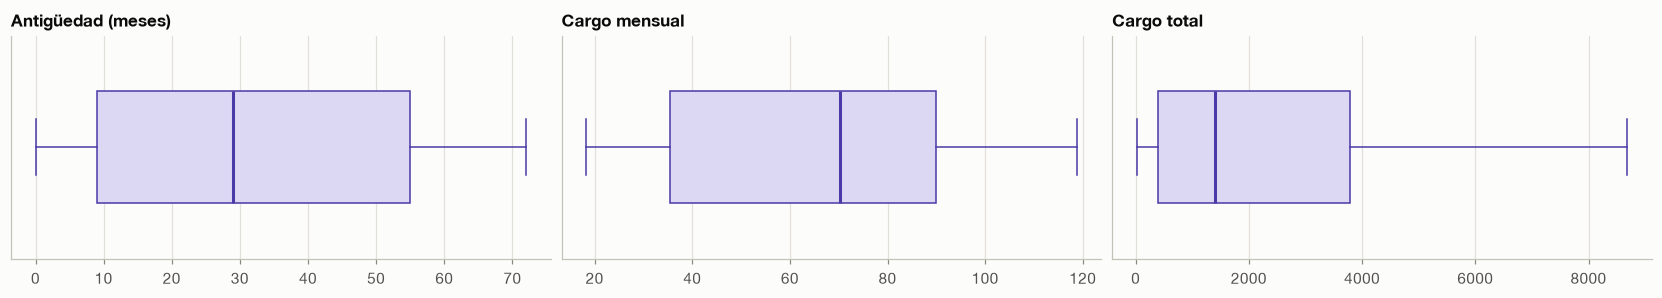

In [13]:
# Usamos la copia exploratoria, con TotalCharges numérico (sus 11 celdas en blanco quedan fuera del cálculo)
# Regla del rango intercuartílico (IQR): atípico = por debajo de Q1 - 1.5·IQR o por encima de Q3 + 1.5·IQR
resumen_atipicos = {}
for col in NUMERICAS:
    q1, q3 = df_eda[col].quantile([0.25, 0.75])
    limite_inferior, limite_superior = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    resumen_atipicos[col] = {
        "mínimo": df_eda[col].min(), "máximo": df_eda[col].max(),
        "límite inferior": limite_inferior, "límite superior": limite_superior,
        "atípicos": int(((df_eda[col] < limite_inferior) | (df_eda[col] > limite_superior)).sum()),
    }
display(pd.DataFrame.from_dict(resumen_atipicos, orient="index").rename(index=NOMBRES).round(2))

# Rangos lógicos: antigüedad entre 0 y 72 meses y cargos mayores que cero
print(f"Antigüedades fuera de 0 a 72 meses: {(~df_eda['tenure'].between(0, 72)).sum()}")
print(f"Cargos mensuales iguales o menores a cero: {(df_eda['MonthlyCharges'] <= 0).sum()}")

# Diagramas de caja: cualquier punto fuera de los bigotes sería un valor atípico
fig, ejes = plt.subplots(1, 3, figsize=(15, 2.6), layout="constrained")
for eje, col in zip(ejes, NUMERICAS):
    eje.boxplot(df_eda[col].dropna(), orientation="horizontal", widths=0.5, patch_artist=True,
                boxprops={"facecolor": "#dcd8f3", "edgecolor": COLOR_NEUTRO},
                medianprops={"color": COLOR_NEUTRO, "linewidth": 2},
                whiskerprops={"color": COLOR_NEUTRO}, capprops={"color": COLOR_NEUTRO},
                flierprops={"marker": "o", "markersize": 4, "markerfacecolor": COLOR_SE_VA, "markeredgecolor": "none"})
    eje.set_title(NOMBRES[col])
    eje.set_yticks([])
    eje.grid(axis="y", visible=False)
plt.show()

Podemos observar que **no hay valores atípicos**: ningún valor queda fuera de los límites del rango intercuartílico, los diagramas de caja no muestran puntos fuera de los bigotes y todos los valores están dentro de rangos lógicos. Los cargos mensuales van de 18 a 119 y la antigüedad llega hasta 6 años, cifras perfectamente razonables.

**Decisión: no eliminar ni modificar ningún registro.** El cargo total tiene una distribución con cola larga hacia los montos altos, pero esos clientes no son errores: son clientes con muchos años en la empresa. Esa forma de la distribución se maneja más adelante al escalar las variables para el modelo.

### Columnas que no aportan al modelo

El identificador del cliente es una clave que no describe ninguna característica. Si lo dejáramos, el modelo podría memorizar clientes en lugar de aprender patrones. Comprobamos que, en efecto, es único para cada cliente.

In [14]:
# Un identificador tiene tantos valores distintos como clientes
print(f"customerID tiene {df_raw['customerID'].nunique():,} valores distintos en {len(df_raw):,} clientes.")

customerID tiene 7,043 valores distintos en 7,043 clientes.


Podemos observar que cada cliente tiene un identificador distinto, así que no aporta ningún patrón que el modelo pueda aprender.

**Decisión: eliminar `customerID`.**

### Resumen de la limpieza

Reunimos todas las decisiones en una tabla y aplicamos la limpieza con la función `limpiar_datos` del proyecto, la misma que usa el script de entrenamiento, para comprobar que el dataset queda listo para el modelo: sin faltantes y con cada variable en el tipo que le corresponde.

In [15]:
# Tabla resumen de las decisiones de limpieza
decisiones_limpieza = pd.DataFrame([
    {"problema": "Tipo incorrecto", "qué encontramos": "TotalCharges leída como texto",
     "decisión": "Convertir a número", "por qué": "Es un monto de dinero"},
    {"problema": "Tipo incorrecto", "qué encontramos": "SeniorCitizen codificada como 0/1",
     "decisión": "Convertir a No/Yes", "por qué": "Misma convención que las demás variables"},
    {"problema": "Valores faltantes", "qué encontramos": "11 clientes sin cargo total, todos con 0 meses",
     "decisión": "Rellenar con 0", "por qué": "Sin meses cumplidos no hay nada cobrado"},
    {"problema": "Duplicados", "qué encontramos": "0 clientes repetidos; 22 perfiles iguales de clientes distintos",
     "decisión": "Conservar", "por qué": "Son clientes reales con un plan común"},
    {"problema": "Valores atípicos", "qué encontramos": "Ninguno por rango intercuartílico ni por rangos lógicos",
     "decisión": "Conservar todos", "por qué": "Todos los valores son plausibles"},
    {"problema": "Columna sin información", "qué encontramos": "customerID es un identificador único",
     "decisión": "Eliminar", "por qué": "Solo permitiría memorizar clientes"},
])
display(decisiones_limpieza.style.hide(axis="index"))

# Aplicamos la limpieza del proyecto y verificamos el resultado
df = limpiar_datos(df_raw)
print(f"Valores faltantes: {df.isna().sum().sum()}")
print(f"Variables numéricas: {df.select_dtypes('number').columns.tolist()}")
print(f"Variables categóricas: {df.drop(columns='Churn').select_dtypes(exclude='number').shape[1]} "
      f"(más la variable objetivo Churn)")

problema,qué encontramos,decisión,por qué
Tipo incorrecto,TotalCharges leída como texto,Convertir a número,Es un monto de dinero
Tipo incorrecto,SeniorCitizen codificada como 0/1,Convertir a No/Yes,Misma convención que las demás variables
Valores faltantes,"11 clientes sin cargo total, todos con 0 meses",Rellenar con 0,Sin meses cumplidos no hay nada cobrado
Duplicados,0 clientes repetidos; 22 perfiles iguales de clientes distintos,Conservar,Son clientes reales con un plan común
Valores atípicos,Ninguno por rango intercuartílico ni por rangos lógicos,Conservar todos,Todos los valores son plausibles
Columna sin información,customerID es un identificador único,Eliminar,Solo permitiría memorizar clientes


Valores faltantes: 0
Variables numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas: 16 (más la variable objetivo Churn)


Podemos observar que el dataset quedó limpio: 7,043 clientes, ningún valor faltante, las tres variables numéricas con tipo numérico y las demás como categorías con una convención uniforme. Dejamos dos redundancias sin cambiar a propósito: la categoría "No internet service", que se repite en seis variables pero es información real (el cliente no tiene internet), y el cargo total, que repite en parte la información de la antigüedad. Quitarlas sería una decisión para una siguiente iteración del modelo, que tendría que probarse antes de aplicarse.

## Conclusión

La exploración deja tres ideas que guían el modelado. La primera es que las clases no están equilibradas: solo se va el 26.5% de los clientes, así que la exactitud engaña, porque un modelo que siempre dijera "se queda" acertaría el 73.5% de las veces sin detectar a nadie. Por eso el script de entrenamiento usa F1 como métrica principal y permite dar más peso a los clientes que se van.

La segunda es que hay señales claras de riesgo. La antigüedad, el tipo de contrato, el internet de fibra óptica, la forma de pago y los servicios de protección son las variables que más separan a quienes se van de quienes se quedan.

La tercera es que los datos necesitan muy poca limpieza: convertir dos tipos, rellenar con 0 el cargo total de los 11 clientes nuevos y quitar el identificador. Esas decisiones viven en `telco_churn/dataset.py`, así que cualquier corrida del script las aplica exactamente igual que este notebook.

El entrenamiento, la comparación de hiperparámetros y el registro en MLflow se hacen con el script `python -m telco_churn.modeling.train`, como se explica en el README del proyecto.

## Referencias

Anthropic. (2026). *Claude* (versión Opus 5.5) [Modelo de lenguaje grande], utilizado mediante Claude Code para generación de código, análisis de datos, depuración y apoyo en la redacción. https://claude.com/claude-code

BlastChar. (2018). *Telco Customer Churn* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn